# Customer Retention & Experimentation Platform
## Milestone 1 — a synthetic randomized experiment

A fictional streaming service, **StreamSphere**, attracts free-trial users around the 2026 World Cup (June 11–July 19). Can an offer help them start paying and stay after the tournament?

This notebook builds the experiment's data, explains its assumptions, and checks the simulator. All people, behavior, costs, and offer effects are invented. They are learning assumptions, not market estimates or evidence about real customers.

**What you will do:** define the experiment, generate pre-offer behavior, randomize offers, simulate outcomes and economics, inspect descriptive charts, and save separate observed and evaluation datasets. We stop before statistical offer comparisons, ML, and dbt.


### 1. Set up the notebook

Run cells from top to bottom. Locally, install `requirements.txt` from the repository root, start Jupyter Lab, and open this notebook. The next cell finds the repository whether Jupyter starts in the root or in `notebooks/`.

**Google Colab:** clone this repository using its actual GitHub URL in a setup cell, then `%cd /content/Customer-decisioning-platform` and run `%pip install -r requirements.txt`. Open this notebook in Colab and run all cells after setup. Alternatively upload the notebook and the `retention/` folder to the same working directory. A notebook upload alone does not include its imported module. Colab's existing NumPy/pandas/Matplotlib are sufficient for the analysis cells.

The Python module holds reusable generation and validation functions. The explanations and inspection stay here. A fixed seed reproduces a run within the same package versions; different seeds create different experiments.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'retention' / 'simulation.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Clone the repository or upload retention/ beside the notebook, then change to that directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from retention.simulation import ARMS, PRE_OFFER_FEATURES, simulate_experiment, validate_experiment

N_CUSTOMERS = 12_000
SEED = 2026
print(f'{N_CUSTOMERS:,} customers; seed={SEED}')
print(f'NumPy {np.__version__}; pandas {pd.__version__}')


Fontconfig error: No writable cache directories


12,000 customers; seed=2026
NumPy 2.3.5; pandas 2.2.3


### 2. Define who enters and what happens when

The unit of randomization is one customer, with one account and one assignment. Signups run from **May 28 through July 5, 2026**. Each customer completes a 14-day free trial and is still eligible immediately before its scheduled end. Thus assignments fall June 11–July 19. We deliberately model this eligible cohort only; early trial cancellations and existing paying subscribers are out of scope.

Pre-offer features summarize the first 14 trial days and are frozen before the offer. Assignment happens on day 0, then each customer receives exactly one offer with probability 25%. Assignment uses an independent random stream and does not depend on behavior. Counts and average behavior should be similar, but need not be identical across arms.

| Assigned offer | What the simulator assumes |
|---|---|
| Control | Standard $15/month plan; no offer cost |
| 20% discount | 20% off the first 30 paid days; then standard price |
| 7-day extension | Seven additional free days; payment can start on day 7; $0.15/day service cost for every assigned customer |
| Plan recommendation | Help finding the standard $15 plan and relevant non-sports content; no price change; $0.10 delivery cost for every assigned customer |

Offers are delivered automatically, with no noncompliance, spillovers, or interference between customers. All costs use fictional USD assumptions.

**Outcomes:** conversion means starting a paid subscription at the customer's offered trial end (day 0, or day 7 for extension). Nonconverters never convert later in this simplified experiment. `retained_day90` means converted and still paying 90 days after assignment; its denominator is **all assigned customers**, not just converters. The 90-day window is common to all arms, so extension users have at most 83 paid days. Everyone receives full follow-up; there is no censoring or reactivation.


### 3. How synthetic behavior and outcomes are created

The generator draws unobserved engagement, sports interest, and price sensitivity between 0 and 1. These invented preferences are not exported as customer features.

* **Active trial days:** a binomial draw over 14 days, with activity probability `0.15 + 0.70 × engagement`.
* **Watch hours:** active days multiplied by a positive random viewing intensity (Gamma shape 2, scale 0.65); inactive customers watch zero hours.
* **Sports viewing share:** sports interest rounded to three decimals; no actual match schedule is modeled.
* **Pricing-page visits:** a Poisson draw with mean `0.3 + 2.5 × price sensitivity`.
* **Discovery sessions:** a binomial draw over active days, with probability `1 − sports interest`, representing exploration beyond sports.

More activity raises conversion and retention; price sensitivity lowers baseline conversion, and sports dependence lowers baseline retention after the event. The discount helps price-sensitive users most, the extension helps less engaged users most, and recommendation helps sports-focused users explore continuing value. Positive offer benefits are deliberately built into this version. Other worlds could have weak or harmful offers.

For reproducibility, the baseline conversion score is `−1.5 + 0.15 × active days + 0.025 × watch hours − 0.9 × price sensitivity`. The conditional retention score is `−0.2 + 0.12 × active days − 1.3 × sports interest`. Scores become probabilities using `1 / (1 + exp(−score))`.

| Offer | Addition to conversion score | Addition to conditional day-90 retention score |
|---|---|---|
| Control | 0 | 0 |
| Discount | `0.15 + 0.95 × price sensitivity` | `0.10 + 0.25 × price sensitivity` |
| Extension | `0.10 + 0.60 × (1 − engagement)` | `0.05 + 0.25 × (1 − engagement)` |
| Recommendation | `0.10 + 0.70 × sports interest` | `0.20 + 0.80 × sports interest` |

Conversion is a random yes/no draw. Converters receive a random cancellation time from a constant daily churn hazard calibrated to the conditional day-90 probability. Daily hazards are a simplification; this version has no tournament-end churn spike, country differences, seasonal trends, missing data, or billing failures. One realized outcome per customer is observed; the other offers' outcomes are not observed.


In [2]:
customers, oracle_answer_key = simulate_experiment(N_CUSTOMERS, SEED)
print(f'Observed dataset: {customers.shape}; separate answer key: {oracle_answer_key.shape}')
display(customers[['customer_id', 'signup_date', *PRE_OFFER_FEATURES, 'assigned_offer']].head())


Observed dataset: (12000, 20); separate answer key: (48000, 5)


,customer_id,signup_date,active_days_pre,watch_hours_pre,sports_share_pre,pricing_page_visits_pre,discovery_sessions_pre,assigned_offer
0,customer_0000001,2026-06-05,7,7.83,0.886,1,1,extension_7days
1,customer_0000002,2026-06-04,9,23.84,0.577,1,5,extension_7days
2,customer_0000003,2026-06-26,8,23.28,0.242,1,4,extension_7days
3,customer_0000004,2026-06-27,7,1.81,0.626,3,4,control
4,customer_0000005,2026-07-04,13,7.34,0.931,2,1,control


The preview shows only a few customers. `_pre` columns are available before assignment. Assignment and outcome columns are stored for later experiment analysis, but they are not baseline predictive features.

The answer key has four rows per customer: probabilities under every possible offer. It includes conversion probability, conditional retention probability **given conversion**, and unconditional retention probability (their product). These are the simulator's ground truth for future evaluation, not observed customer attributes. Keep the answer key separate from training and analysis inputs. It contains probabilities, not realized counterfactual outcomes.


In [3]:
# Explicit feature boundary for a future milestone; no model is trained here.
pre_offer_features = customers.loc[:, list(PRE_OFFER_FEATURES)].copy()
assert not any(c.startswith('p_') for c in customers.columns)
assert set(pre_offer_features.columns) == set(PRE_OFFER_FEATURES)
print('Baseline feature columns:', ', '.join(pre_offer_features.columns))


Baseline feature columns: active_days_pre, watch_hours_pre, sports_share_pre, pricing_page_visits_pre, discovery_sessions_pre


### 4. Understand the revenue ledger

The follow-up window runs from assignment through day 90, excluding the end boundary for accrual. One month is treated as 30 days, so the standard daily price is **$0.50**. A cancellation after `k` paid daily intervals earns `k` days of revenue. Retained customers earn the entire available paid window. This is prorated revenue, not an upfront subscription cash-flow ledger.

`gross_revenue_90` = paid days × $0.50 at the reference list price, **before discount**.

`discount_cost_90` = 20% × $0.50 × first min(30, paid days), for converted discount users only. `delivery_cost_90` = $1.05 for every extension user, $0.10 for every recommendation user, otherwise zero.

`offer_cost_90` = discount cost + delivery cost. `net_revenue_90` = reference gross revenue − offer cost. Discount forgone revenue is subtracted exactly once. Extension forgone billing is already reflected in its shorter paid window and is not subtracted again. Nonconverting extension or recommendation users can have negative net revenue because delivery still costs money.

This metric is revenue after incremental offer costs, **not profit**: acquisition, baseline hosting, licensing, taxes, refunds, and fixed costs are omitted.


In [4]:
ledger_columns = ['assigned_offer', 'converted', 'retained_day90', 'conversion_day',
                  'paid_days_90', 'gross_revenue_90', 'discount_cost_90',
                  'delivery_cost_90', 'offer_cost_90', 'net_revenue_90']
# Show converters and nonconverters from each arm without dumping a large dataset.
display(customers.groupby(['assigned_offer', 'converted'], sort=False).head(1)[ledger_columns].round(2))


,assigned_offer,converted,retained_day90,conversion_day,paid_days_90,gross_revenue_90,discount_cost_90,delivery_cost_90,offer_cost_90,net_revenue_90
0,extension_7days,False,False,NaN,0,0.0,0.0,1.05,1.05,-1.05
1,extension_7days,True,True,7.0,83,41.5,0.0,1.05,1.05,40.45
3,control,False,False,NaN,0,0.0,0.0,0.00,0.00,0.00
5,plan_recommendation,True,True,0.0,90,45.0,0.0,0.10,0.10,44.90
7,plan_recommendation,False,False,NaN,0,0.0,0.0,0.10,0.10,-0.10
12,discount_20pct,False,False,NaN,0,0.0,0.0,0.00,0.00,0.00
14,control,True,False,0.0,36,18.0,0.0,0.00,0.00,18.00
15,discount_20pct,True,False,0.0,16,8.0,1.6,0.00,1.60,6.40


### 5. Check that the simulator obeys the design

These checks catch broken IDs and time windows, retention without conversion, invalid oracle probabilities, leaked probability columns, and incorrect offer costs or revenue. They check data integrity rather than whether a particular offer wins.


In [5]:
validate_experiment(customers, oracle_answer_key)
print('Timeline, outcome, oracle separation, and revenue checks passed.')


Timeline, outcome, oracle separation, and revenue checks passed.


### 6. Inspect randomization and pre-offer balance

Each arm should receive about a quarter of the cohort. The table compares baseline behavior before any offer can affect it. Small differences are normal random variation. For a readable scale comparison, the second table expresses each arm's deviation from the overall mean in units of the overall feature standard deviation; zero means exact equality. This is a simulator diagnostic, not a hypothesis test or a reason to rerandomize until balance looks perfect.


,customers,share
assigned_offer,,
control,2983,0.249
discount_20pct,3069,0.256
extension_7days,2884,0.240
plan_recommendation,3064,0.255


,active_days_pre,watch_hours_pre,sports_share_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,
control,7.03,9.10,0.59,1.55,2.85
discount_20pct,7.04,9.21,0.60,1.56,2.83
extension_7days,6.99,9.21,0.60,1.51,2.78
plan_recommendation,7.04,9.03,0.60,1.56,2.88


,active_days_pre,watch_hours_pre,sports_share_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,
control,0.002,-0.004,-0.004,0.006,0.008
discount_20pct,0.006,0.010,-0.003,0.010,-0.004
extension_7days,-0.013,0.009,0.007,-0.028,-0.023
plan_recommendation,0.004,-0.014,-0.000,0.011,0.018


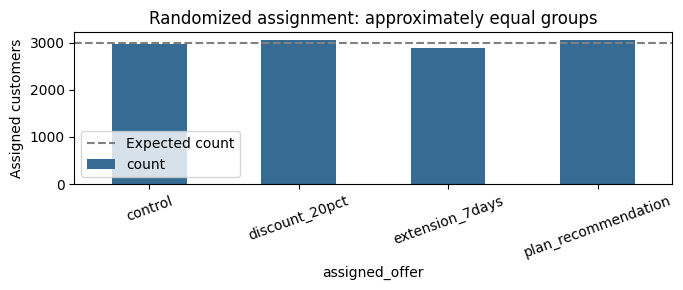

In [6]:
counts = customers.assigned_offer.value_counts().reindex(ARMS)
balance = customers.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].mean().reindex(ARMS)
display(pd.DataFrame({'customers': counts, 'share': counts / N_CUSTOMERS}).round(3))
display(balance.round(2))
standardized_deviations = (balance - customers[list(PRE_OFFER_FEATURES)].mean()) / customers[list(PRE_OFFER_FEATURES)].std()
display(standardized_deviations.round(3))
counts.plot.bar(color='#366b93', figsize=(7, 3), rot=20)
plt.axhline(N_CUSTOMERS / 4, color='gray', linestyle='--', label='Expected count')
plt.ylabel('Assigned customers')
plt.title('Randomized assignment: approximately equal groups')
plt.legend()
plt.tight_layout()
plt.show()


### 7. Inspect realized outcomes and costs

Rates and average dollars below use **all assigned customers** in each arm, including nonconverters. Retention must be lower than or equal to conversion. A higher conversion rate can coexist with higher costs and lower net revenue. The discount costs at most $3 per converted customer; the extension shortens the paid window.

These are descriptive simulator outputs. Do not treat this seed's ordering as an offer recommendation or a statistically supported result. Formal effect estimates, uncertainty, multiple-comparison handling, and appropriate A/B testing belong to the next milestone. Retention comparisons restricted to converters would condition on a post-treatment outcome and require additional care.


,customers,conversion_rate,retained_day90_rate,average_offer_cost,average_net_revenue
assigned_offer,,,,,
control,2983,0.353,0.167,0.000,11.252
discount_20pct,3069,0.504,0.281,1.372,15.827
extension_7days,2884,0.446,0.229,1.050,12.476
plan_recommendation,3064,0.448,0.301,0.100,16.531


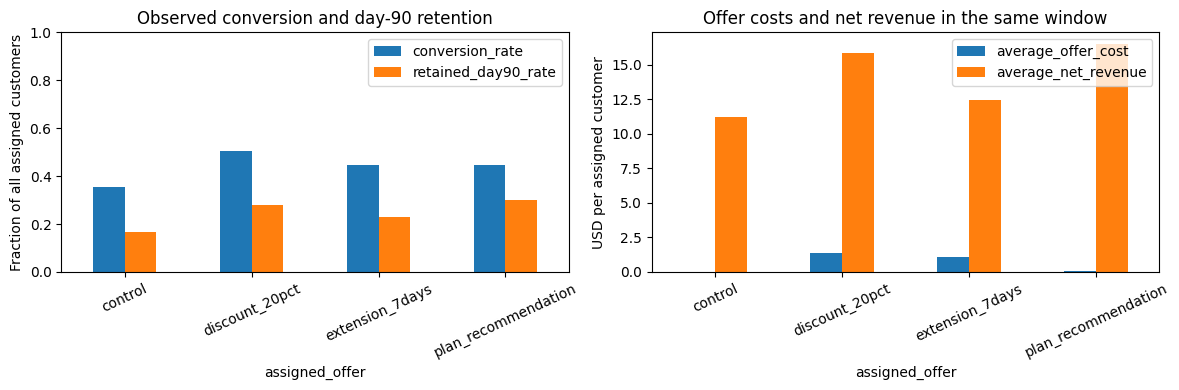

In [7]:
summary = customers.groupby('assigned_offer').agg(
    customers=('customer_id', 'size'),
    conversion_rate=('converted', 'mean'),
    retained_day90_rate=('retained_day90', 'mean'),
    average_offer_cost=('offer_cost_90', 'mean'),
    average_net_revenue=('net_revenue_90', 'mean'),
).reindex(ARMS)
display(summary.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary[['conversion_rate', 'retained_day90_rate']].plot.bar(ax=axes[0], rot=25)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Fraction of all assigned customers')
axes[0].set_title('Observed conversion and day-90 retention')
summary[['average_offer_cost', 'average_net_revenue']].plot.bar(ax=axes[1], rot=25)
axes[1].set_ylabel('USD per assigned customer')
axes[1].set_title('Offer costs and net revenue in the same window')
plt.tight_layout()
plt.show()


### 8. Evaluation-only answer-key check

We now briefly open the separate answer key to check whether the simulator's random draws match their expected probabilities. We select only each customer's assigned arm and compare average expected probabilities with realized rates. They should be reasonably close, not exactly equal; individual outcomes remain random. The four-offer key is kept intact for later evaluation, but is never added to `pre_offer_features` or `customers`.

This checks the data-generating process, not a trained model or an A/B-test conclusion.


In [8]:
evaluation_only = customers[['customer_id', 'assigned_offer', 'converted', 'retained_day90']].merge(
    oracle_answer_key,
    left_on=['customer_id', 'assigned_offer'], right_on=['customer_id', 'offer'],
    validate='one_to_one',
)
calibration = evaluation_only.groupby('assigned_offer').agg(
    expected_conversion=('p_conversion', 'mean'), observed_conversion=('converted', 'mean'),
    expected_retention=('p_retained_day90', 'mean'), observed_retention=('retained_day90', 'mean'),
).reindex(ARMS)
display(calibration.round(3))
del evaluation_only  # Do not carry a probability-enriched table into later training.


,expected_conversion,observed_conversion,expected_retention,observed_retention
assigned_offer,,,,
control,0.347,0.353,0.172,0.167
discount_20pct,0.490,0.504,0.267,0.281
extension_7days,0.437,0.446,0.229,0.229
plan_recommendation,0.463,0.448,0.300,0.301


### 9. Save local data without putting it in Git

The next cell writes the observed experiment and the oracle to different folders, both under ignored `data/`. It also records the seed, sample size, and package versions. Re-running overwrites this run's local files. The notebook keeps small previews, tables, and charts, not the complete dataset in its outputs.

For later modeling, use only the explicit pre-offer feature allowlist. Customer IDs support joins; dates support cohort audits; assignment identifies treatment; outcomes are labels or experiment metrics. None of those automatically becomes a pre-offer feature. The oracle is for evaluation only, and should never be loaded into a training pipeline.


In [9]:
import json
observed_dir = ROOT / 'data' / 'generated'
oracle_dir = ROOT / 'data' / 'evaluation_only'
observed_dir.mkdir(parents=True, exist_ok=True)
oracle_dir.mkdir(parents=True, exist_ok=True)
customers.to_csv(observed_dir / 'customers.csv', index=False)
oracle_answer_key.to_csv(oracle_dir / 'oracle_probabilities.csv', index=False)
metadata = {'n_customers': N_CUSTOMERS, 'seed': SEED, 'numpy': np.__version__,
            'pandas': pd.__version__, 'followup_days': 90,
            'pre_offer_features': list(PRE_OFFER_FEATURES)}
(observed_dir / 'run_metadata.json').write_text(json.dumps(metadata, indent=2) + '\n')
print('Saved observed customers and a separate evaluation-only answer key under ignored data/.')


Saved observed customers and a separate evaluation-only answer key under ignored data/.


### What to inspect and what comes later

Check the assumptions first: eligible cohort, offer policies, common 90-day clock, behavioral response, and prorated revenue. Then inspect the balance table and the outcome/cost table. Try another seed to see sampling variation, or change `N_CUSTOMERS` and run all cells again.

The test suite (`python -m pytest -q`) also checks deterministic reproduction, small cohorts, invalid inputs, randomized balance, probability calibration on a larger cohort, and whether validation catches corrupted revenue or leaked probabilities.

**Milestone 1 ends here.** The later roadmap is randomized experiment analysis and appropriate A/B testing, a model estimating which customers benefit from each offer, and dbt transformations. Those are intentionally not implemented yet.
